# Benford's Law in Bulgarian Retail Prices

## Abstract

*Placeholder. We will write this at the end, when all results are in.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src import benford

## Problem

Benford's law says that in many real data sets the first digit is not random. Small first digits, like 1 and 2, are much more common than large ones, like 8 and 9. Frank Benford found this pattern in many tables, such as river areas, city populations and physical constants (Benford, 1938).

Prices are different. A price is not measured, it is chosen by a store. Stores often set prices just below a round number. A price of 1.99 instead of 2.00 moves the first digit from 2 to 1. A price of 9.99 instead of 10.00 moves it from 1 to 9. Habits like this can change how often each first digit appears.

This project asks two questions:

1. Do real retail prices from Bulgarian store brochures follow Benford's law?
2. If they do not, what does the gap tell us about how stores set prices?

## Theory

### Benford's law

The first digit of a number is its first digit that is not zero. For 12.90 it is 1, for 3.49 it is 3, and for 0.45 it is 4.

The pattern was first noticed by Newcomb (1881) and later tested on many data sets by Benford (1938). The law says that the chance that the first digit equals $d$ is

$$P(d) = \log_{10}\left(1 + \frac{1}{d}\right), \qquad d = 1, 2, \dots, 9.$$

In words: take $1 + 1/d$ and find its base-10 logarithm. When $d$ is small, $1 + 1/d$ is large, so small digits get large chances.

The table below shows the nine values.

In [2]:
expected = benford.expected_benford()

table = pd.DataFrame({"P(d)": expected.round(4), "percent": (100 * expected).round(1)})
table.index.name = "d"
print("Sum of all nine:", round(expected.sum(), 6))
table

Sum of all nine: 1.0


,P(d),percent
d,,
1,0.3010,30.1
2,0.1761,17.6
3,0.1249,12.5
4,0.0969,9.7
5,0.0792,7.9
6,0.0669,6.7
7,0.0580,5.8
8,0.0512,5.1
9,0.0458,4.6


The chance gets smaller with every digit from 1 to 9. The nine values add up to 1, as they should.

### Why the law appears

**Data spread over several orders of magnitude.** An order of magnitude is a step of ×10, for example from 1 to 10 or from 10 to 100. Look at one such step on a log scale. The numbers that start with 1 (from 1 to 2) take up $\log_{10} 2$ of the step. The numbers that start with 9 (from 9 to 10) take up only $\log_{10}(10/9)$. In general, the numbers that start with $d$ take up $\log_{10}(d+1) - \log_{10} d = \log_{10}(1 + 1/d)$, which is exactly $P(d)$. So if data are spread smoothly over several steps, each digit gets the share from the table.

**Scale invariance.** A law about first digits should not depend on the unit. If we change all prices from leva to euros, or from euros to dollars, the share of each first digit should stay the same. Pinkham (1961) showed that Benford's law is the only first-digit law with this property. Hill (1995) also showed that when numbers from many different sources are mixed, the result tends to follow Benford's law. Berger and Hill (2011) give the full theory.

### A short derivation

Write any positive number $x$ as

$$x = m \cdot 10^k, \qquad 1 \le m < 10,$$

where $k$ is a whole number. Here $m$ is $x$ with the decimal point moved so that it falls between 1 and 10. For 0.45 we get $m = 4.5$ and $k = -1$. The first digit of $x$ is $d$ exactly when $d \le m < d + 1$.

Now take $\log_{10}$ of both sides:

$$\log_{10} x = k + \log_{10} m, \qquad 0 \le \log_{10} m < 1.$$

So $\log_{10} m$ is what is left of $\log_{10} x$ after we remove the whole number $k$. It is called the fractional part of $\log_{10} x$.

The key assumption is that this fractional part is uniform on $[0, 1)$, which means every value between 0 and 1 is equally likely. This is close to true when the data are spread smoothly over several orders of magnitude. Then

$$P(d) = P\big(\log_{10} d \le \log_{10} m < \log_{10}(d+1)\big) = \log_{10}(d+1) - \log_{10} d = \log_{10}\left(1 + \frac{1}{d}\right).$$

For a uniform value, the chance to land in an interval equals the length of the interval. Here the length is $\log_{10}(d+1) - \log_{10} d$, which simplifies to the law. If we add all nine values, the terms cancel in pairs and we get $\log_{10} 10 - \log_{10} 1 = 1$.

### The chi-square goodness of fit test

We need a way to measure how far real data are from the law. Let $N$ be the number of prices. For each digit $d$, let $O_d$ be how many prices start with $d$ (observed), and let $E_d = N \cdot P(d)$ be how many the law predicts (expected). The test statistic is

$$\chi^2 = \sum_{d=1}^{9} \frac{(O_d - E_d)^2}{E_d}.$$

For each digit we take the gap between the observed and the expected count, square it, and divide by the expected count. Then we add up the nine numbers. A small $\chi^2$ means the data are close to the law, a large one means they are far from it.

The null hypothesis $H_0$ is that the first digits follow Benford's law. If $H_0$ is true, $\chi^2$ follows a chi-square distribution with 8 degrees of freedom.

**Why 8 degrees of freedom.** There are 9 digits, so 9 counts. But the counts must add up to $N$. Once we know 8 of them, the 9th is fixed, so only 8 can change freely. We do not estimate anything from the data, because the values $P(d)$ come straight from the formula. So nothing more is taken away, and we get $9 - 1 = 8$.

**p-value.** The p-value is the chance to get a $\chi^2$ this large or larger if the law is true. If it is below 0.05, we reject $H_0$. With 8 degrees of freedom this happens when $\chi^2$ is above the critical value below.

In [3]:
critical = stats.chi2.ppf(0.95, df=8)
print("Critical value at the 5% level, 8 degrees of freedom:", round(critical, 3))

Critical value at the 5% level, 8 degrees of freedom: 15.507


Two things to keep in mind:

- The test is only reliable when every expected count $E_d$ is at least about 5. For the smallest stores this may not hold.
- With many data points, even a tiny gap gives a small p-value. So a rejection tells us that the gap is real, not that it is large. We also need to look at how big the gaps are.

### Where the law is used

The best known use is fraud detection. Auditors compare the first digits in accounting and tax data with Benford's law (Nigrini, 1999; Nigrini, 2012). People who make up numbers tend to use all digits too evenly, so invented data often has too few 1s. A gap from the law does not prove fraud, but it shows where to look closer. The law has also been used to check election results, with mixed success (Deckert, Myagkov and Ordeshook, 2011).

### When the law fails

The law does not hold for every data set. It usually fails when:

- **The range is narrow.** Adult heights in centimetres almost all start with 1.
- **Numbers are assigned, not measured.** Phone numbers, postal codes and invoice numbers have no reason to follow the law.
- **There are fixed limits.** Values that cannot go above or below a set amount pile up near that amount.
- **People choose the numbers.** Prices set just below round numbers, like 9.99, push some digits up and others down. This is exactly what we want to test.
- **The sample is small.** With few numbers, random noise hides the pattern.

The closest work to ours is by Sehity, Hoelzl and Kirchler (2005). They used Benford's law to study psychological prices before and after the euro was introduced.

## Data

The prices come from public store brochures. Stores in Bulgaria print these brochures every week to show their offers. The site shopi.bg collects them in one place, and our data was taken from there.

Each row is one product in one brochure. There are two columns:

- `price` - the price of the product
- `store` - the store that printed the brochure

Before the analysis we clean the data. We drop rows where the price is missing or is not a number. We also drop prices that are zero or negative, because a real price must be positive and zero has no first digit. Last, we drop prices of exactly 0.01. A one-cent price is not a real shelf price, it looks like a placeholder in the brochure data.

In [4]:
raw = pd.read_csv("data/prices.csv")
prices = benford.clean_prices(raw)

print("Rows before cleaning:", len(raw))
print("One-cent prices:     ", (raw["price"] == 0.01).sum())
print("Rows after cleaning: ", len(prices))
print("Rows removed:        ", len(raw) - len(prices))

Rows before cleaning: 52164
One-cent prices:      46
Rows after cleaning:  52118
Rows removed:         46


All removed rows are the one-cent prices, because the two counts above are equal. So the rest of the export was already clean.

Here is how many prices we have from each store.

In [5]:
prices["store"].value_counts().rename("prices").to_frame()

,prices
store,
Kaufland,21842
Lidl,9863
Billa,7696
Lilly,3325
Dar,2201
T-Market,2098
BulMag,1766
Fantastico,1764
Metro,1199


Below is a histogram of all prices. Cheap products are much more common than expensive ones, so on a normal scale most bars would be squeezed on the left. We use a log scale on the x axis instead. On a log scale, the distance from 1 to 10 is the same as from 10 to 100, so all price ranges are easy to see.

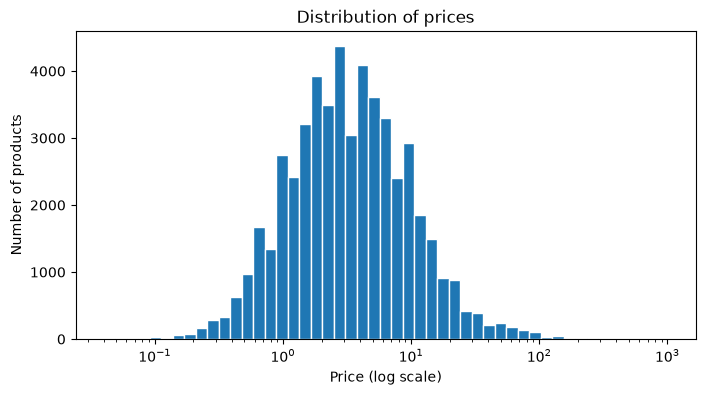

In [6]:
# Bins with equal width on the log scale
bins = np.logspace(np.log10(prices["price"].min()), np.log10(prices["price"].max()), 50)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(prices["price"], bins=bins, edgecolor="white")
ax.set_xscale("log")
ax.set_xlabel("Price (log scale)")
ax.set_ylabel("Number of products")
ax.set_title("Distribution of prices")
plt.show()

## Method

The code is in `src/benford.py`. Three functions do the work:

- `first_digit(prices)` finds the first significant digit of each price.
- `expected_benford()` gives the nine probabilities $P(d)$ from the Theory section.
- `compare_to_benford(prices)` counts how many prices start with each digit, computes the expected counts $E_d = N \cdot P(d)$, and runs the chi-square test with scipy.

To find the first digit, we write the number as text, drop the leading zeros and the decimal point, and take the first character. We do not use the formula $m = x / 10^k$ from the derivation here. Computers store numbers like 0.3 with a tiny error, so the division can land just below the right digit. The cell below shows this.

In [7]:
print("0.3 / 0.1 =", 0.3 / 0.1)

examples = [0.89, 0.3, 3.49, 12.90, 0.045, 100]
pd.DataFrame({"number": examples, "first digit": benford.first_digit(examples)})

0.3 / 0.1 = 2.9999999999999996


,number,first digit
0,0.890,8
1,0.300,3
2,3.490,3
3,12.900,1
4,0.045,4
5,100.000,1


So 0.3 / 0.1 is not exactly 3, and its whole part would be 2. The text method gives the right first digit for every example.

### Check on data that follows the law: powers of 2

Before we test the prices, we check the code on numbers that are known to follow Benford's law. The powers of 2 (2, 4, 8, 16, 32, ...) are such numbers. The reason is that $\log_{10} 2^n = n \cdot \log_{10} 2$. The number $\log_{10} 2$ is irrational, so the fractional parts of $n \cdot \log_{10} 2$ spread evenly over $[0, 1)$ as $n$ grows. This is exactly the assumption from our derivation.

We take the first 1000 powers, from $2^1$ to $2^{1000}$.

In [8]:
powers = 2.0 ** np.arange(1, 1001)
counts2, chi2_2, p_2 = benford.compare_to_benford(powers)

print(f"Chi-square: {chi2_2:.3f}")
print(f"p-value:    {p_2:.6f}")
counts2.round(1)

Chi-square: 0.159
p-value:    0.999998


,observed,expected
digit,,
1,301,301.0
2,176,176.1
3,125,124.9
4,97,96.9
5,79,79.2
6,69,66.9
7,56,58.0
8,52,51.2
9,45,45.8


The observed counts are almost the same as the expected ones. The chi-square value 0.159 is far below the critical value 15.507, and the p-value is close to 1. So the test does not reject the law, as it should for powers of 2. This shows that the functions count the digits and run the test correctly.

The fit is even closer than we would expect from random data. This is because powers of 2 are not random: their fractional parts fill $[0, 1)$ very evenly.

## References

1. Newcomb, S. (1881). Note on the frequency of use of the different digits in natural numbers. *American Journal of Mathematics*, 4(1), 39-40. https://doi.org/10.2307/2369148
2. Benford, F. (1938). The law of anomalous numbers. *Proceedings of the American Philosophical Society*, 78(4), 551-572. https://www.jstor.org/stable/984802
3. Pinkham, R. S. (1961). On the distribution of first significant digits. *The Annals of Mathematical Statistics*, 32(4), 1223-1230. https://doi.org/10.1214/aoms/1177704862
4. Hill, T. P. (1995). A statistical derivation of the significant-digit law. *Statistical Science*, 10(4), 354-363. https://doi.org/10.1214/ss/1177009869
5. Berger, A., and Hill, T. P. (2011). A basic theory of Benford's law. *Probability Surveys*, 8, 1-126. https://doi.org/10.1214/11-PS175
6. Nigrini, M. J. (1999). I've got your number. *Journal of Accountancy*, May 1999. https://www.journalofaccountancy.com/issues/1999/may/nigrini/
7. Nigrini, M. J. (2012). *Benford's Law: Applications for Forensic Accounting, Auditing, and Fraud Detection*. Wiley. https://doi.org/10.1002/9781119203094
8. Deckert, J., Myagkov, M., and Ordeshook, P. C. (2011). Benford's law and the detection of election fraud. *Political Analysis*, 19(3), 245-268. https://doi.org/10.1093/pan/mpr014
9. Sehity, T., Hoelzl, E., and Kirchler, E. (2005). Price developments after a nominal shock: Benford's law and psychological pricing after the euro introduction. *International Journal of Research in Marketing*, 22(4), 471-480. https://doi.org/10.1016/j.ijresmar.2005.09.002
10. Benford's law. Wikipedia. https://en.wikipedia.org/wiki/Benford%27s_law
11. Pearson's chi-squared test. Wikipedia. https://en.wikipedia.org/wiki/Pearson%27s_chi-squared_test
12. shopi.bg, the source of the brochure data. https://shopi.bg